# 1. Configuração do ambiente

In [1]:
import os
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')

from google.colab import drive
drive.mount('/content/drive')

PASTA = '/content/drive/MyDrive/tcc_resultados_v5/'
os.makedirs(PASTA, exist_ok=True)

Mounted at /content/drive


# 2. Leitura dos dados brutos (PNS 2019)

In [2]:
caminho_arquivo = '/content/drive/MyDrive/pns2019.csv'

colunas_interesse = [
    'C008', 'C006', 'Q068', 'Q00201', 'Q03001', 'Q060',
    'Q06306', 'P034', 'P050', 'P052', 'P00104', 'P00404'
]

df = pd.read_csv(caminho_arquivo, sep=',', usecols=colunas_interesse, low_memory=False)
print(f'{df.shape[0]} linhas e {df.shape[1]} colunas')

293726 linhas e 12 colunas


### Variáveis

- Q068: diagnóstico de AVC (variável alvo)
- C008 e C006: idade e sexo
- P00104 e P00404: peso e altura, usados no cálculo do IMC
- Q00201, Q03001, Q060 e Q06306: hipertensão, diabetes, colesterol alto e doença do coração
- P034, P050 e P052: exercício físico e tabagismo

## 2.1 Fluxo de registros e códigos de resposta

In [3]:
bruto = df.copy()
com_q068 = bruto.dropna(subset=['Q068'])
adultos = com_q068[com_q068['C008'] >= 18]

print('arquivo bruto:', len(bruto))
print('com resposta à Q068:', len(com_q068))
print('adultos:', len(adultos))
print('respondentes com menos de 18 anos:', len(com_q068) - len(adultos))
print('idade mínima entre os respondentes:', com_q068['C008'].min())

for col in ['Q068', 'C006', 'Q00201', 'Q03001', 'Q060', 'Q06306', 'P034', 'P050', 'P052']:
    print(f'\n{col}')
    print(adultos[col].value_counts(dropna=False).sort_index().to_string())

peso, altura = adultos['P00104'], adultos['P00404']
print('\npeso ausente:', peso.isna().sum(), '| fora de [20, 300]:', ((peso < 20) | (peso > 300)).sum())
print('altura ausente:', altura.isna().sum(), '| fora de [50, 250]:', ((altura < 50) | (altura > 250)).sum())
peso_ok = peso.where((peso >= 20) & (peso <= 300))
altura_ok = altura.where((altura >= 50) & (altura <= 250))
imc = peso_ok / ((altura_ok / 100) ** 2)
print('imc fora de [12, 60]:', ((imc < 12) | (imc > 60)).sum())
imc = imc.where((imc >= 12) & (imc <= 60))
print(f'imc imputado: {imc.isna().sum()} ({imc.isna().mean():.2%}), mediana = {imc.median():.2f}')

arquivo bruto: 293726
com resposta à Q068: 90846
adultos: 88531
respondentes com menos de 18 anos: 2315
idade mínima entre os respondentes: 15.0

Q068
Q068
1.0     1974
2.0    86557

C006
C006
1.0    41662
2.0    46869

Q00201
Q00201
1.0    23819
2.0    63043
NaN     1669

Q03001
Q03001
1.0     7358
2.0    74991
NaN     6182

Q060
Q060
1.0    13396
2.0    67855
NaN     7280

Q06306
Q06306
1.0     4711
2.0    83820

P034
P034
1.0    34894
2.0    53637

P050
P050
1.0    10124
2.0     1162
3.0    77245

P052
P052
1.0    20993
2.0     2957
3.0    53295
NaN    11286

peso ausente: 853 | fora de [20, 300]: 0
altura ausente: 853 | fora de [50, 250]: 0
imc fora de [12, 60]: 1
imc imputado: 854 (0.96%), mediana = 25.91


# 3. Tratamento inicial e filtro de idade

In [4]:
dicionario_nomes = {
    'Q068': 'avc',
    'C008': 'idade',
    'C006': 'sexo',
    'Q00201': 'hipertensao',
    'Q03001': 'diabetes',
    'Q060': 'colesterol_alto',
    'Q06306': 'doenca_coracao',
    'P034': 'pratica_exercicio',
    'P050': 'fuma_atualmente',
    'P052': 'fumou_passado',
    'P00104': 'peso',
    'P00404': 'altura'
}
df.rename(columns=dicionario_nomes, inplace=True)

df.dropna(subset=['avc'], inplace=True)
df['avc'] = df['avc'].apply(lambda x: 1 if x == 1 else 0)

df = df[df['idade'] >= 18]

df['sexo'] = df['sexo'].apply(lambda x: 0 if x == 1 else 1)

doencas = ['hipertensao', 'diabetes', 'colesterol_alto', 'doenca_coracao', 'pratica_exercicio']
for col in doencas:
    df[col] = df[col].fillna(2)
    df[col] = df[col].apply(lambda x: 1 if x == 1 else 0)

print(f'linhas restantes: {df.shape[0]}')

linhas restantes: 88531


# 4. Engenharia de atributos (IMC e tabagismo)

In [5]:
def calcular_tabagismo(row):
    atual = row['fuma_atualmente']
    passado = row['fumou_passado']
    if atual in (1, 2):
        return 2
    if atual == 3:
        if passado in (1, 2):
            return 1
        if passado == 3:
            return 0
    return 0

df['tabagismo'] = df.apply(calcular_tabagismo, axis=1)

df['peso_limpo'] = df['peso'].apply(lambda x: np.nan if (x > 300 or x < 20) else x)
df['altura_limpa'] = df['altura'].apply(lambda x: np.nan if (x > 250 or x < 50) else x)

df['imc'] = df['peso_limpo'] / ((df['altura_limpa'] / 100) ** 2)
df['imc'] = df['imc'].apply(lambda x: np.nan if (x < 12 or x > 60) else x)
df['imc'] = df['imc'].fillna(df['imc'].median())

df.drop(columns=['fuma_atualmente', 'fumou_passado', 'peso_limpo', 'altura_limpa'], inplace=True)

colunas_finais = [
    'sexo', 'idade', 'peso', 'altura', 'imc',
    'pratica_exercicio', 'hipertensao', 'diabetes',
    'colesterol_alto', 'doenca_coracao', 'tabagismo', 'avc'
]
df = df[colunas_finais]

# 5. Exportação do dataset final

In [6]:
caminho_saida = '/content/drive/MyDrive/dataset_avc_limpo_tcc_v5.csv'
df.to_csv(caminho_saida, index=False)

print(f'{df.shape[0]} linhas x {df.shape[1]} colunas')
display(df.describe())
display(df.head(10))

88531 linhas x 12 colunas


,sexo,idade,peso,altura,imc,pratica_exercicio,hipertensao,diabetes,colesterol_alto,doenca_coracao,tabagismo,avc
count,88531.000000,88531.000000,87678.000000,87678.000000,88531.000000,88531.000000,88531.000000,88531.000000,88531.000000,88531.000000,88531.000000,88531.000000
mean,0.529408,47.188013,72.182440,164.880529,26.491862,0.394144,0.269047,0.083112,0.151314,0.053213,0.525488,0.022297
std,0.499137,17.118721,15.106083,9.718126,4.763146,0.488669,0.443467,0.276053,0.358357,0.224459,0.710153,0.147649
min,0.000000,18.000000,25.000000,128.000000,12.802768,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,33.000000,62.000000,158.000000,23.243802,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,1.000000,46.000000,70.000000,165.000000,25.910684,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,1.000000,60.000000,81.000000,171.000000,29.069767,1.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000
max,1.000000,107.000000,176.000000,206.000000,56.923596,1.000000,1.000000,1.000000,1.000000,1.000000,2.000000,1.000000


,sexo,idade,peso,altura,imc,pratica_exercicio,hipertensao,diabetes,colesterol_alto,doenca_coracao,tabagismo,avc
0,1,55.0,60.0,145.0,28.537455,1,1,0,1,0,1,0
9,1,19.0,65.0,152.0,28.133657,0,0,0,0,0,2,0
10,1,45.0,77.0,155.0,32.049948,0,0,0,0,0,1,0
18,1,58.0,56.0,159.0,22.151023,1,0,0,0,0,0,0
19,1,28.0,55.0,176.0,17.755682,1,0,0,0,0,0,0
21,0,81.0,81.0,174.0,26.753864,0,1,0,0,0,1,0
22,1,41.0,75.0,170.0,25.951557,1,0,0,0,0,0,0
26,1,38.0,60.0,156.0,24.654832,0,0,0,0,0,2,0
29,0,33.0,80.0,172.0,27.041644,1,0,0,0,0,1,0
31,0,81.0,75.0,162.0,28.577961,0,1,1,0,0,1,0


## 5.1 Análise exploratória

prevalência de AVC: 2.23% (1974 de 88531)

faixa_etaria
                  n  casos  prevalencia_%
faixa_etaria                             
18-29         15394     42           0.27
30-39         18150     88           0.48
40-49         16602    202           1.22
50-59         15657    371           2.37
60-69         12555    515           4.10
70-79          7157    504           7.04
80+            3016    252           8.36 

sexo
               n  casos  prevalencia_%
Masculino  41662    930           2.23
Feminino   46869   1044           2.23 

hipertensao
         n  casos  prevalencia_%
Não  64712    604           0.93
Sim  23819   1370           5.75 

diabetes
         n  casos  prevalencia_%
Não  81173   1477           1.82
Sim   7358    497           6.75 

colesterol_alto
         n  casos  prevalencia_%
Não  75135   1318           1.75
Sim  13396    656           4.90 

doenca_coracao
         n  casos  prevalencia_%
Não  83820   1452           1.73
Sim   4711    522  

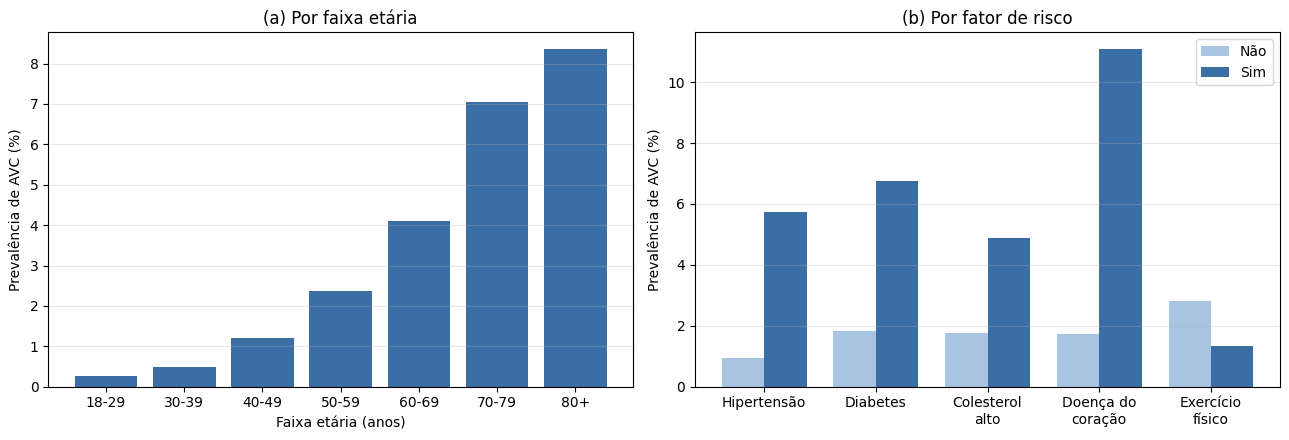

In [7]:
eda = df.copy()
eda['faixa_etaria'] = pd.cut(eda['idade'], bins=[17, 29, 39, 49, 59, 69, 79, 200],
                             labels=['18-29', '30-39', '40-49', '50-59', '60-69', '70-79', '80+'])

fatores = {
    'faixa_etaria': None,
    'sexo': {0: 'Masculino', 1: 'Feminino'},
    'hipertensao': {0: 'Não', 1: 'Sim'},
    'diabetes': {0: 'Não', 1: 'Sim'},
    'colesterol_alto': {0: 'Não', 1: 'Sim'},
    'doenca_coracao': {0: 'Não', 1: 'Sim'},
    'pratica_exercicio': {0: 'Não', 1: 'Sim'},
    'tabagismo': {0: 'Nunca fumou', 1: 'Ex-fumante', 2: 'Fumante atual'},
}

print(f"prevalência de AVC: {100 * eda['avc'].mean():.2f}% ({eda['avc'].sum()} de {len(eda)})\n")
tabelas = {}
for col, rotulos in fatores.items():
    t = eda.groupby(col, observed=False)['avc'].agg(n='size', casos='sum')
    t['prevalencia_%'] = 100 * t['casos'] / t['n']
    if rotulos:
        t.index = [rotulos[i] for i in t.index]
    tabelas[col] = t
    print(col)
    print(t.round(2).to_string(), '\n')
pd.concat(tabelas).round(2).to_csv(PASTA + 'eda_prevalencias.csv')

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
t = tabelas['faixa_etaria']
axes[0].bar(t.index.astype(str), t['prevalencia_%'], color='#3b6ea5')
axes[0].set_xlabel('Faixa etária (anos)')
axes[0].set_ylabel('Prevalência de AVC (%)')
axes[0].set_title('(a) Por faixa etária')

binarios = ['hipertensao', 'diabetes', 'colesterol_alto', 'doenca_coracao', 'pratica_exercicio']
nomes = ['Hipertensão', 'Diabetes', 'Colesterol\nalto', 'Doença do\ncoração', 'Exercício\nfísico']
x = np.arange(len(binarios))
w = 0.38
axes[1].bar(x - w / 2, [tabelas[c].loc['Não', 'prevalencia_%'] for c in binarios], w, label='Não', color='#a8c4e0')
axes[1].bar(x + w / 2, [tabelas[c].loc['Sim', 'prevalencia_%'] for c in binarios], w, label='Sim', color='#3b6ea5')
axes[1].set_xticks(x)
axes[1].set_xticklabels(nomes)
axes[1].set_ylabel('Prevalência de AVC (%)')
axes[1].set_title('(b) Por fator de risco')
axes[1].legend()
for ax in axes:
    ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(PASTA + 'eda_prevalencia.png', dpi=300)
plt.show()

idade e imc por classe (0 = sem AVC, 1 = com AVC)
avc                 0        1
idade count  86557.00  1974.00
      mean      46.81    63.80
      std       16.98    14.90
      min       18.00    18.00
      25%       33.00    54.00
      50%       45.00    65.00
      75%       59.00    74.00
      max      107.00   104.00
imc   count  86557.00  1974.00
      mean      26.48    26.90
      std        4.76     5.08
      min       12.80    14.10
      25%       23.24    23.44
      50%       25.91    26.37
      75%       29.07    29.75
      max       56.92    50.20


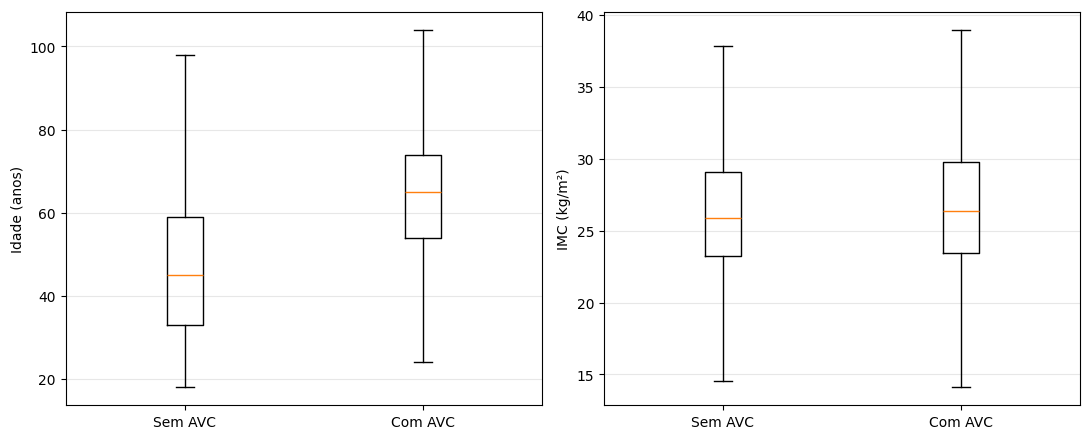


correlação de Pearson
                   idade   sexo    imc  pratica_exercicio  hipertensao  diabetes  colesterol_alto  doenca_coracao  tabagismo    avc
idade              1.000  0.027  0.053             -0.170        0.429     0.247            0.226           0.191      0.135  0.147
sexo               0.027  1.000  0.025             -0.052        0.093     0.048            0.106           0.017     -0.109 -0.000
imc                0.053  0.025  1.000             -0.008        0.199     0.104            0.104           0.036     -0.044  0.013
pratica_exercicio -0.170 -0.052 -0.008              1.000       -0.079    -0.063            0.004          -0.040     -0.113 -0.049
hipertensao        0.429  0.093  0.199             -0.079        1.000     0.263            0.263           0.198      0.045  0.145
diabetes           0.247  0.048  0.104             -0.063        0.263     1.000            0.209           0.119      0.025  0.092
colesterol_alto    0.226  0.106  0.104              0

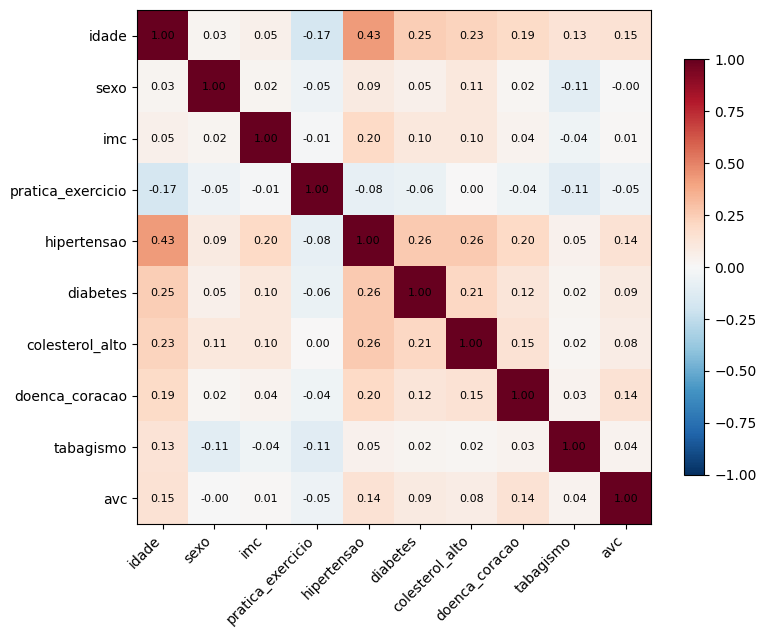

In [8]:
print('idade e imc por classe (0 = sem AVC, 1 = com AVC)')
print(eda.groupby('avc')[['idade', 'imc']].describe().T.round(2).to_string())

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, col, rotulo in [(axes[0], 'idade', 'Idade (anos)'), (axes[1], 'imc', 'IMC (kg/m²)')]:
    ax.boxplot([eda.loc[eda['avc'] == 0, col], eda.loc[eda['avc'] == 1, col]], showfliers=False)
    ax.set_xticks([1, 2])
    ax.set_xticklabels(['Sem AVC', 'Com AVC'])
    ax.set_ylabel(rotulo)
    ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(PASTA + 'eda_idade_imc.png', dpi=300)
plt.show()

cols = ['idade', 'sexo', 'imc', 'pratica_exercicio', 'hipertensao', 'diabetes', 'colesterol_alto', 'doenca_coracao', 'tabagismo', 'avc']
corr = eda[cols].corr()
print('\ncorrelação de Pearson')
print(corr.round(3).to_string())
corr.round(4).to_csv(PASTA + 'eda_correlacao.csv')

fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)))
ax.set_xticklabels(cols, rotation=45, ha='right')
ax.set_yticks(range(len(cols)))
ax.set_yticklabels(cols)
for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=8)
fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.savefig(PASTA + 'eda_correlacao.png', dpi=300)
plt.show()

# 6. Divisão treino/teste e SMOTE

In [9]:
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE

X = df.drop(columns=['avc', 'peso', 'altura'])
y = df['avc']

X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)

smote = SMOTE(random_state=42)
X_treino_balanceado, y_treino_balanceado = smote.fit_resample(X_treino, y_treino)

print('treino antes do smote:')
print(y_treino.value_counts())
print('\ntreino depois do smote:')
print(y_treino_balanceado.value_counts())
print('\nteste:')
print(y_teste.value_counts())

treino antes do smote:
avc
0    69245
1     1579
Name: count, dtype: int64

treino depois do smote:
avc
0    69245
1    69245
Name: count, dtype: int64

teste:
avc
0    17312
1      395
Name: count, dtype: int64


# 7. Padronização e treinamento dos modelos

In [10]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier

scaler = StandardScaler()
X_treino_bal_scaled = scaler.fit_transform(X_treino_balanceado)
X_teste_scaled = scaler.transform(X_teste)

modelos = {
    'Regressão Logística': LogisticRegression(random_state=42, max_iter=1000),
    'Random Forest': RandomForestClassifier(random_state=42, n_jobs=-1),
    'KNN': KNeighborsClassifier(n_neighbors=5, n_jobs=-1),
    'XGBoost': XGBClassifier(random_state=42, eval_metric='logloss'),
}

for nome, modelo in modelos.items():
    t0 = time.time()
    modelo.fit(X_treino_bal_scaled, y_treino_balanceado)
    print(f'{nome}: {time.time() - t0:.2f} s')

Regressão Logística: 0.18 s
Random Forest: 24.76 s
KNN: 0.46 s
XGBoost: 1.56 s


# 8. Avaliação no conjunto de teste

Regressão Logística
              precision    recall  f1-score   support

           0       0.99      0.73      0.84     17312
           1       0.05      0.66      0.10       395

    accuracy                           0.73     17707
   macro avg       0.52      0.69      0.47     17707
weighted avg       0.97      0.73      0.82     17707

Random Forest
              precision    recall  f1-score   support

           0       0.98      0.95      0.96     17312
           1       0.04      0.11      0.06       395

    accuracy                           0.93     17707
   macro avg       0.51      0.53      0.51     17707
weighted avg       0.96      0.93      0.94     17707

KNN
              precision    recall  f1-score   support

           0       0.98      0.85      0.91     17312
           1       0.04      0.30      0.08       395

    accuracy                           0.84     17707
   macro avg       0.51      0.58      0.49     17707
weighted avg       0.96      0.84   

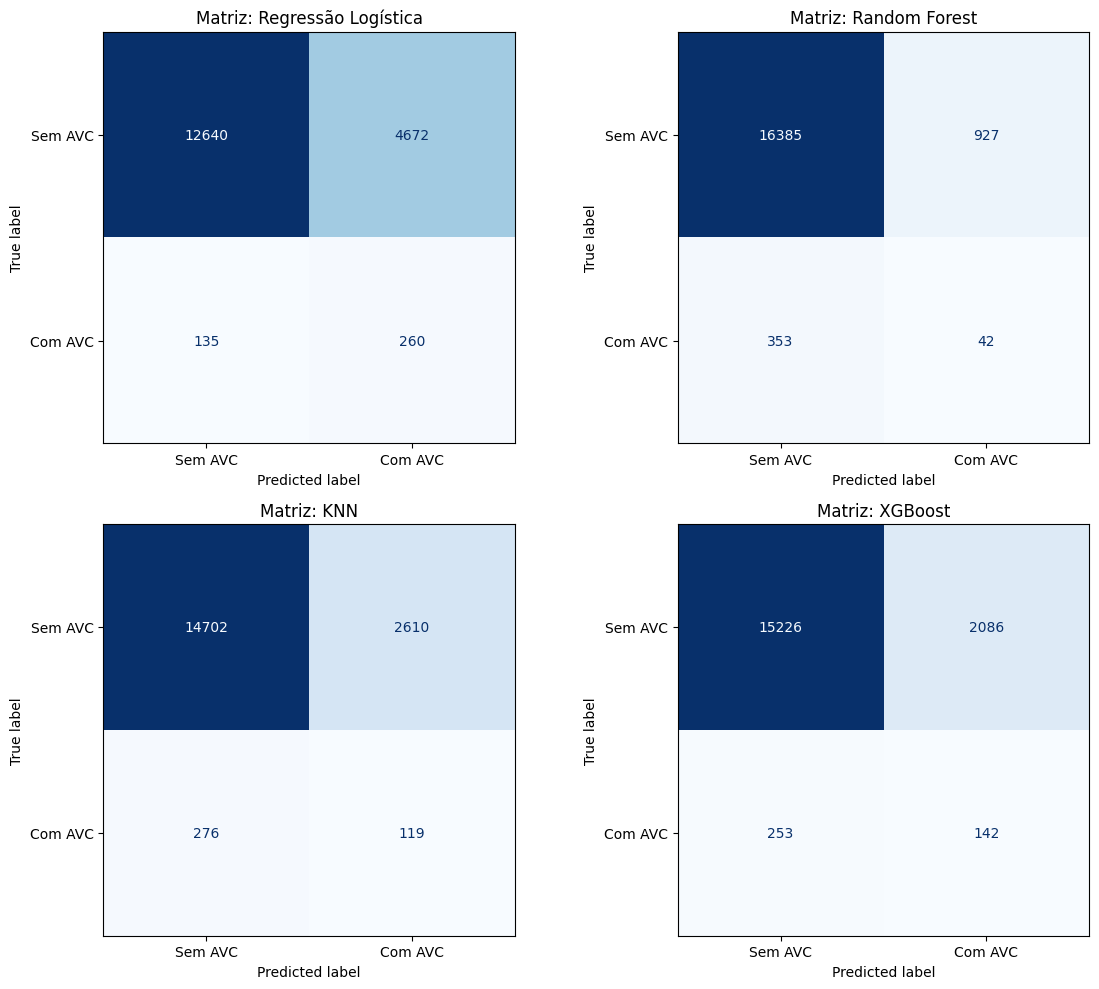

In [11]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for idx, (nome, modelo) in enumerate(modelos.items()):
    y_pred = modelo.predict(X_teste_scaled)
    print(nome)
    print(classification_report(y_teste, y_pred))

    cm = confusion_matrix(y_teste, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Sem AVC', 'Com AVC'])
    disp.plot(ax=axes[idx], cmap='Blues', colorbar=False)
    axes[idx].set_title(f'Matriz: {nome}')

plt.tight_layout()
plt.savefig(PASTA + 'matrizes_confusao.png', dpi=300)
plt.show()

# 9. Experimentos complementares

In [12]:
from sklearn.base import clone

def avaliar(y_true, y_pred):
    vn, fp, fn, vp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    recall = vp / (vp + fn) if vp + fn else 0.0
    precisao = vp / (vp + fp) if vp + fp else 0.0
    especificidade = vn / (vn + fp) if vn + fp else 0.0
    f1 = 2 * precisao * recall / (precisao + recall) if precisao + recall else 0.0
    return {'recall': recall, 'precisao': precisao, 'f1': f1, 'especificidade': especificidade,
            'acur_bal': (recall + especificidade) / 2, 'acuracia': (vp + vn) / (vp + vn + fp + fn),
            'VP': vp, 'FN': fn, 'FP': fp, 'VN': vn}

def tabela(resultados):
    return pd.DataFrame(resultados).T.sort_values('recall', ascending=False)

res_smote = {nome: avaliar(y_teste, m.predict(X_teste_scaled)) for nome, m in modelos.items()}
t_smote = tabela(res_smote)
print(t_smote.round(3).to_string())
t_smote.round(4).to_csv(PASTA + 'resultados_smote.csv')

                     recall  precisao     f1  especificidade  acur_bal  acuracia     VP     FN      FP       VN
Regressão Logística   0.658     0.053  0.098           0.730     0.694     0.729  260.0  135.0  4672.0  12640.0
XGBoost               0.359     0.064  0.108           0.880     0.619     0.868  142.0  253.0  2086.0  15226.0
KNN                   0.301     0.044  0.076           0.849     0.575     0.837  119.0  276.0  2610.0  14702.0
Random Forest         0.106     0.043  0.062           0.946     0.526     0.928   42.0  353.0   927.0  16385.0


## 9.1 Sem balanceamento

In [13]:
scaler_sem = StandardScaler()
X_treino_scaled_sem = scaler_sem.fit_transform(X_treino)
X_teste_scaled_sem = scaler_sem.transform(X_teste)

res_sem = {}
for nome, m in modelos.items():
    modelo = clone(m)
    t0 = time.time()
    modelo.fit(X_treino_scaled_sem, y_treino)
    res_sem[nome] = avaliar(y_teste, modelo.predict(X_teste_scaled_sem))
    res_sem[nome]['tempo_s'] = time.time() - t0

t_sem = tabela(res_sem)
print(t_sem.round(3).to_string())
t_sem.round(4).to_csv(PASTA + 'resultados_sem_smote.csv')

                     recall  precisao     f1  especificidade  acur_bal  acuracia   VP     FN    FP       VN  tempo_s
Random Forest         0.013     0.067  0.021           0.996     0.504     0.974  5.0  390.0  70.0  17242.0    5.838
KNN                   0.005     0.133  0.010           0.999     0.502     0.977  2.0  393.0  13.0  17299.0    3.536
XGBoost               0.005     0.143  0.010           0.999     0.502     0.977  2.0  393.0  12.0  17300.0    2.842
Regressão Logística   0.000     0.000  0.000           1.000     0.500     0.978  0.0  395.0   0.0  17312.0    0.143


## 9.2 Ponderação de classes

In [14]:
peso_pos = (y_treino == 0).sum() / (y_treino == 1).sum()
print(f'scale_pos_weight = {peso_pos:.2f}')

modelos_peso = {
    'Regressão Logística': LogisticRegression(random_state=42, max_iter=1000, class_weight='balanced'),
    'Random Forest': RandomForestClassifier(random_state=42, n_jobs=-1, class_weight='balanced'),
    'XGBoost': XGBClassifier(random_state=42, eval_metric='logloss', scale_pos_weight=peso_pos),
}

res_peso = {}
for nome, modelo in modelos_peso.items():
    t0 = time.time()
    modelo.fit(X_treino_scaled_sem, y_treino)
    res_peso[nome] = avaliar(y_teste, modelo.predict(X_teste_scaled_sem))
    res_peso[nome]['tempo_s'] = time.time() - t0

t_peso = tabela(res_peso)
print(t_peso.round(3).to_string())
t_peso.round(4).to_csv(PASTA + 'resultados_class_weight.csv')

comparacao = pd.DataFrame({
    'recall_sem_smote': t_sem['recall'],
    'recall_smote': t_smote['recall'],
    'recall_class_weight': t_peso['recall'],
}).sort_values('recall_smote', ascending=False).round(3)
print('\nrecall nos três cenários')
print(comparacao.to_string())
comparacao.to_csv(PASTA + 'comparacao_cenarios_recall.csv')

scale_pos_weight = 43.85
                     recall  precisao     f1  especificidade  acur_bal  acuracia     VP     FN      FP       VN  tempo_s
Regressão Logística   0.777     0.066  0.122           0.751     0.764     0.752  307.0   88.0  4312.0  13000.0    0.253
XGBoost               0.504     0.071  0.124           0.849     0.677     0.842  199.0  196.0  2607.0  14705.0    0.572
Random Forest         0.010     0.059  0.017           0.996     0.503     0.974    4.0  391.0    64.0  17248.0    5.891

recall nos três cenários
                     recall_sem_smote  recall_smote  recall_class_weight
Regressão Logística             0.000         0.658                0.777
XGBoost                         0.005         0.359                0.504
KNN                             0.005         0.301                  NaN
Random Forest                   0.013         0.106                0.010


## 9.3 Curvas ROC e precisão-sensibilidade

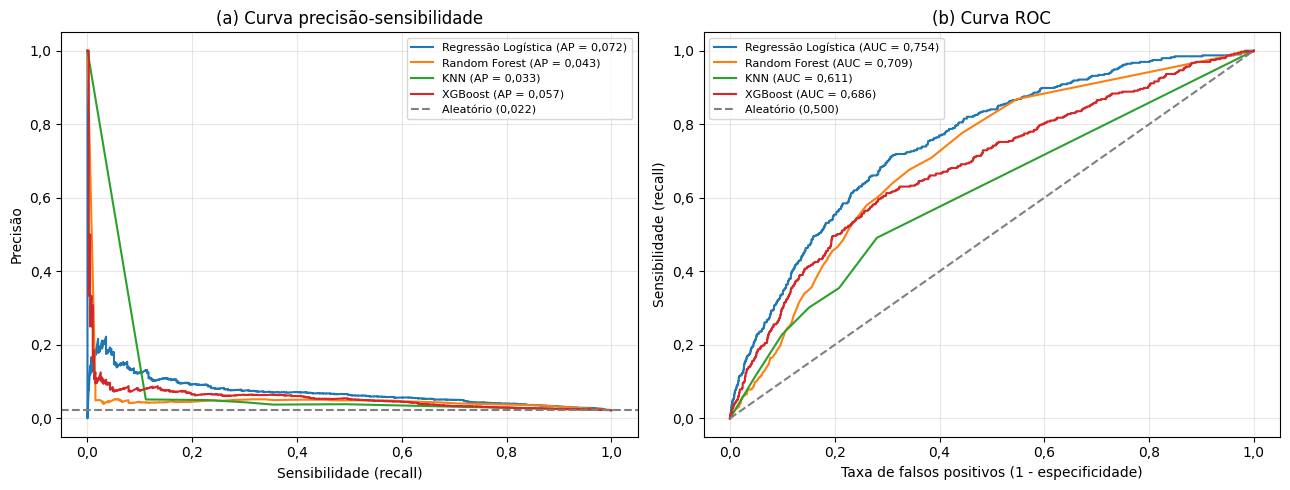

                     AUC_PR (average precision)  AUC_ROC
Regressão Logística                       0.072    0.754
XGBoost                                   0.057    0.686
Random Forest                             0.043    0.709
KNN                                       0.033    0.611


In [15]:
from matplotlib.ticker import FuncFormatter
from sklearn.metrics import precision_recall_curve, roc_curve, average_precision_score, roc_auc_score

def virgula(v, casas=3):
    return f'{v:.{casas}f}'.replace('.', ',')

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
areas = {}
for nome, m in modelos.items():
    prob = m.predict_proba(X_teste_scaled)[:, 1]
    precisao, recall, _ = precision_recall_curve(y_teste, prob)
    fpr, tpr, _ = roc_curve(y_teste, prob)
    ap, auc = average_precision_score(y_teste, prob), roc_auc_score(y_teste, prob)
    areas[nome] = {'AUC_PR (average precision)': ap, 'AUC_ROC': auc}
    axes[0].plot(recall, precisao, label=f'{nome} (AP = {virgula(ap)})')
    axes[1].plot(fpr, tpr, label=f'{nome} (AUC = {virgula(auc)})')

prevalencia = y_teste.mean()
axes[0].axhline(prevalencia, ls='--', color='gray', label=f'Aleatório ({virgula(prevalencia)})')
axes[0].set_xlabel('Sensibilidade (recall)')
axes[0].set_ylabel('Precisão')
axes[0].set_title('(a) Curva precisão-sensibilidade')
axes[1].plot([0, 1], [0, 1], ls='--', color='gray', label='Aleatório (0,500)')
axes[1].set_xlabel('Taxa de falsos positivos (1 - especificidade)')
axes[1].set_ylabel('Sensibilidade (recall)')
axes[1].set_title('(b) Curva ROC')
for ax in axes:
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: virgula(v, 1)))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: virgula(v, 1)))
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(PASTA + 'curvas_pr_roc.png', dpi=300)
plt.show()

t_areas = pd.DataFrame(areas).T.sort_values('AUC_PR (average precision)', ascending=False)
print(t_areas.round(3).to_string())
t_areas.round(4).to_csv(PASTA + 'areas_pr_roc.csv')

## 9.4 Ajuste do limiar de decisão

In [16]:
X_sub, X_val, y_sub, y_val = train_test_split(X_treino, y_treino, test_size=0.20, stratify=y_treino, random_state=42)
X_sub_bal, y_sub_bal = SMOTE(random_state=42).fit_resample(X_sub, y_sub)
sc_val = StandardScaler().fit(X_sub_bal)
limiares = np.round(np.arange(0.05, 0.96, 0.05), 2)

resumo = {}
for nome in ['Regressão Logística', 'XGBoost', 'Random Forest']:
    modelo = clone(modelos[nome]).fit(sc_val.transform(X_sub_bal), y_sub_bal)
    p_val = modelo.predict_proba(sc_val.transform(X_val))[:, 1]
    curva = pd.DataFrame({l: avaliar(y_val, (p_val >= l).astype(int)) for l in limiares}).T.astype(float)
    print(f'{nome} (validação)')
    print(curva[['recall', 'precisao', 'f1', 'especificidade']].round(3).to_string(), '\n')
    arquivo = {'Regressão Logística': 'lr', 'XGBoost': 'xgb', 'Random Forest': 'rf'}[nome]
    curva.round(4).to_csv(PASTA + f'limiares_validacao_{arquivo}.csv')

    l_f1 = curva['f1'].idxmax()
    atinge_80 = curva[curva['recall'] >= 0.80]
    l_r80 = atinge_80.index.max() if len(atinge_80) else None

    p_teste = modelo.predict_proba(sc_val.transform(X_teste))[:, 1]
    resumo[f'{nome} | limiar 0,50'] = avaliar(y_teste, (p_teste >= 0.5).astype(int))
    resumo[f'{nome} | limiar {l_f1:.2f}'.replace('.', ',') + ' (maior F1 na validação)'] = avaliar(y_teste, (p_teste >= l_f1).astype(int))
    if l_r80 is not None:
        resumo[f'{nome} | limiar {l_r80:.2f}'.replace('.', ',') + ' (recall >= 0,80 na validação)'] = avaliar(y_teste, (p_teste >= l_r80).astype(int))

t_limiar = pd.DataFrame(resumo).T
print('teste com os limiares escolhidos na validação')
print(t_limiar.round(3).to_string())
t_limiar.round(4).to_csv(PASTA + 'resultados_limiar.csv')

Regressão Logística (validação)
      recall  precisao     f1  especificidade
0.05   0.991     0.024  0.047           0.091
0.10   0.953     0.027  0.053           0.217
0.15   0.911     0.030  0.058           0.324
0.20   0.858     0.032  0.062           0.407
0.25   0.832     0.035  0.068           0.483
0.30   0.807     0.039  0.075           0.547
0.35   0.769     0.042  0.081           0.605
0.40   0.712     0.045  0.085           0.657
0.45   0.665     0.048  0.090           0.702
0.50   0.633     0.054  0.100           0.747
0.55   0.582     0.059  0.107           0.787
0.60   0.541     0.066  0.117           0.824
0.65   0.484     0.072  0.126           0.858
0.70   0.421     0.079  0.133           0.888
0.75   0.354     0.090  0.144           0.918
0.80   0.272     0.103  0.149           0.946
0.85   0.177     0.121  0.144           0.971
0.90   0.089     0.141  0.109           0.988
0.95   0.019     0.286  0.036           0.999 

XGBoost (validação)
      recall  precisao    

## 9.5 Validação cruzada

In [17]:
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
metricas = {'recall': 'recall', 'precisao': 'precision', 'f1': 'f1',
            'acur_bal': 'balanced_accuracy', 'acuracia': 'accuracy'}

linhas = {}
for nome, m in modelos.items():
    pipe = ImbPipeline([('smote', SMOTE(random_state=42)), ('scaler', StandardScaler()), ('modelo', clone(m))])
    t0 = time.time()
    r = cross_validate(pipe, X_treino, y_treino, cv=cv, scoring=metricas)
    linhas[nome] = {k: f"{r['test_' + k].mean():.3f} ± {r['test_' + k].std():.3f}" for k in metricas}
    print(f'{nome}: {time.time() - t0:.1f} s')

t_cv = pd.DataFrame(linhas).T
print(t_cv.to_string())
t_cv.to_csv(PASTA + 'validacao_cruzada.csv')

Regressão Logística: 1.3 s
Random Forest: 84.3 s
KNN: 21.5 s
XGBoost: 6.3 s
                            recall       precisao             f1       acur_bal       acuracia
Regressão Logística  0.646 ± 0.024  0.053 ± 0.002  0.098 ± 0.004  0.691 ± 0.013  0.734 ± 0.005
Random Forest        0.118 ± 0.008  0.050 ± 0.003  0.070 ± 0.004  0.533 ± 0.004  0.930 ± 0.002
KNN                  0.298 ± 0.020  0.043 ± 0.002  0.075 ± 0.004  0.573 ± 0.008  0.835 ± 0.004
XGBoost              0.303 ± 0.022  0.059 ± 0.003  0.098 ± 0.005  0.596 ± 0.010  0.876 ± 0.003


## 9.6 Fatores associados ao AVC

                     coef      OR  IC95_inf  IC95_sup  p_valor
sexo              -0.1982  0.8202    0.7380    0.9115   0.0002
idade              0.0377  1.0385    1.0346    1.0423   0.0000
imc               -0.0022  0.9978    0.9870    1.0087   0.6857
pratica_exercicio -0.3951  0.6736    0.5962    0.7610   0.0000
hipertensao        1.0347  2.8143    2.4847    3.1877   0.0000
diabetes           0.3586  1.4313    1.2595    1.6265   0.0000
colesterol_alto    0.2080  1.2312    1.0937    1.3861   0.0006
doenca_coracao     1.1046  3.0181    2.6637    3.4197   0.0000
tabagismo          0.1721  1.1878    1.1027    1.2794   0.0000


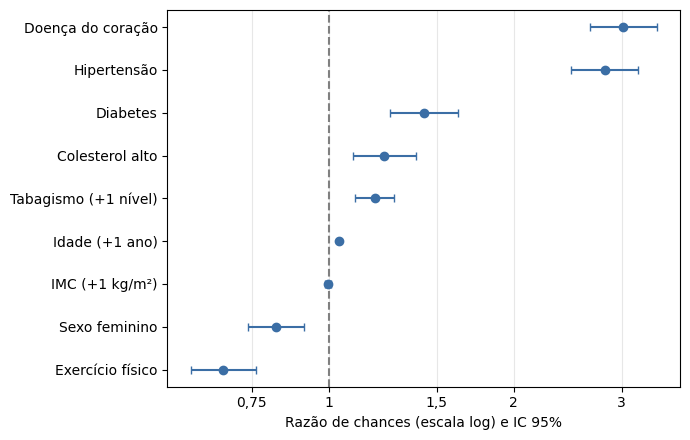


importância dos atributos
                   coef_LR_padronizado_SMOTE  importancia_RF  importancia_XGB
idade                                 0.9231          0.4593           0.1806
imc                                   0.0810          0.3161           0.0565
pratica_exercicio                    -0.6691          0.0855           0.3617
hipertensao                           0.4000          0.0466           0.0950
tabagismo                            -0.2259          0.0350           0.0804
sexo                                 -0.3826          0.0251           0.0880
colesterol_alto                      -0.0963          0.0114           0.0386
doenca_coracao                        0.1092          0.0110           0.0478
diabetes                             -0.1478          0.0101           0.0514


In [18]:
import statsmodels.api as sm
from matplotlib.ticker import FixedLocator, FixedFormatter, NullLocator

logit = sm.Logit(y_treino.astype(float), sm.add_constant(X_treino.astype(float))).fit(disp=0)
ic = np.exp(logit.conf_int())
razoes = pd.DataFrame({
    'coef': logit.params,
    'OR': np.exp(logit.params),
    'IC95_inf': ic[0],
    'IC95_sup': ic[1],
    'p_valor': logit.pvalues,
}).drop('const')
print(razoes.round(4).to_string())
razoes.round(4).to_csv(PASTA + 'razoes_de_chance.csv')

fig, ax = plt.subplots(figsize=(7, 4.5))
ordem = razoes.sort_values('OR')
ax.errorbar(ordem['OR'], range(len(ordem)),
            xerr=[ordem['OR'] - ordem['IC95_inf'], ordem['IC95_sup'] - ordem['OR']],
            fmt='o', color='#3b6ea5', capsize=3)
ax.axvline(1, ls='--', color='gray')
ax.set_yticks(range(len(ordem)))
nomes_or = {'sexo': 'Sexo feminino', 'idade': 'Idade (+1 ano)', 'imc': 'IMC (+1 kg/m²)', 'pratica_exercicio': 'Exercício físico',
            'hipertensao': 'Hipertensão', 'diabetes': 'Diabetes', 'colesterol_alto': 'Colesterol alto', 'doenca_coracao': 'Doença do coração', 'tabagismo': 'Tabagismo (+1 nível)'}
ax.set_yticklabels([nomes_or[c] for c in ordem.index])
ax.set_xscale('log')
marcas = [m for m in [0.25, 0.5, 0.75, 1, 1.5, 2, 3, 4, 6, 8] if ordem['IC95_inf'].min() * 0.9 <= m <= ordem['IC95_sup'].max() * 1.1]
ax.xaxis.set_major_locator(FixedLocator(marcas))
ax.xaxis.set_major_formatter(FixedFormatter([f'{m:g}'.replace('.', ',') for m in marcas]))
ax.xaxis.set_minor_locator(NullLocator())
ax.set_xlabel('Razão de chances (escala log) e IC 95%')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig(PASTA + 'razoes_de_chance.png', dpi=300)
plt.show()

importancia = pd.DataFrame({
    'coef_LR_padronizado_SMOTE': modelos['Regressão Logística'].coef_[0],
    'importancia_RF': modelos['Random Forest'].feature_importances_,
    'importancia_XGB': modelos['XGBoost'].feature_importances_,
}, index=X_treino.columns).sort_values('importancia_RF', ascending=False)
print('\nimportância dos atributos')
print(importancia.round(4).to_string())
importancia.round(4).to_csv(PASTA + 'importancia_variaveis.csv')

## Versões das bibliotecas

In [19]:
import sys, platform
import numpy, pandas, sklearn, imblearn, xgboost, matplotlib, statsmodels

print(f'Python        {sys.version.split()[0]} ({platform.platform()})')
for nome, mod in [('numpy', numpy), ('pandas', pandas), ('scikit-learn', sklearn), ('imbalanced-learn', imblearn),
                  ('xgboost', xgboost), ('matplotlib', matplotlib), ('statsmodels', statsmodels)]:
    print(f'{nome:<14}{mod.__version__}')

Python        3.13.18 (Linux-6.6.159+-x86_64-with-glibc2.39)
numpy         2.4.6
pandas        2.2.3
scikit-learn  1.6.1
imbalanced-learn0.14.2
xgboost       3.4.1
matplotlib    3.10.0
statsmodels   0.15.0
